# ETHICS Religion Persona — Analisis Akurasi v4 (Persona-First)

Notebook ini adalah lapisan penyajian di atas bundle v3 agama yang tervalidasi.
Inferensi tidak dihitung ulang. Akurasi penuh dan seluruh nilai uji statistik
dibaca dari tabel v3; status respons dan token dihitung sebagai ringkasan
deskriptif dari CSV sumber yang dirujuk manifest v3. Empat subset—Commonsense,
Deontology, Justice, dan Virtue—selalu dipertahankan terpisah.

## 0. Provenance dan validation gate

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

start = Path.cwd().resolve()
REPO_ROOT = next(path for path in [start, *start.parents] if (path / "AGENTS.md").exists() and (path / "src").exists())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.MAIN_PARSING.ETHICS.build_religion_publication_notebook_v4_accuracy_persona_first import run_analysis

result = run_analysis()
OUTPUT_DIR = Path(result["output_dir"])
FIGURE_DIR = OUTPUT_DIR / "figures"
display(pd.DataFrame([result["validation"]]).T.rename(columns={0: "value"}))
assert result["validation"]["valid"]
assert result["validation"]["api_calls"] == 0
assert result["validation"]["statistics_recomputed"] is False

,value
valid,True
analysis_version,ethics-religion-v4-accuracy-persona-first-2026...
source_analysis_version,ethics-religion-v3-accuracy-paired-holm-20260822
rows_processed,154428
question_count,1514
model_count,6
condition_count,17
models,"[qwen_qwen3-next-80b-a3b-thinking, meta-llama_..."
conditions,"[neutral, islam_explicit, islam_implicit_1, is..."
subset_question_counts,"{'commonsense': 388, 'deontology': 359, 'justi..."


## 1. Akurasi N, E, I1, I2, dan I3 untuk setiap subset

Tabel berikut memuat seluruh 408 kombinasi model × kondisi × subset. `accuracy_full`
berasal dari tabel v3 dengan seluruh respons sebagai penyebut. `accuracy_committed`
ditampilkan sebagai metrik tambahan dan tidak menggantikan akurasi penuh.

In [2]:
pd.set_option("display.max_rows", 1000)
display(result["accuracy_all_conditions"])

,subset,subset_label,model,model_label,persona,persona_label,identity,identity_label,scenario,total,...,commit_rate,abstain_rate,missing_rate,accuracy_committed,commit_rate_pct,abstain_rate_pct,missing_rate_pct,accuracy_committed_pct,construct_valid,interpretation_note
0,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,neutral,Netral,neutral,Netral,N,388,...,0.976804,0.010309,0.012887,0.646438,97.680412,1.030928,1.288660,64.643799,True,Ketepatan keputusan biner; label 1 berarti tin...
1,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,islam_explicit,Islam E,islam,Islam,E,388,...,0.979381,0.005155,0.015464,0.657895,97.938144,0.515464,1.546392,65.789474,True,Ketepatan keputusan biner; label 1 berarti tin...
2,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,islam_implicit_1,Islam I1,islam,Islam,I1,388,...,0.850515,0.136598,0.012887,0.593939,85.051546,13.659794,1.288660,59.393939,True,Ketepatan keputusan biner; label 1 berarti tin...
3,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,islam_implicit_2,Islam I2,islam,Islam,I2,388,...,0.865979,0.128866,0.005155,0.595238,86.597938,12.886598,0.515464,59.523810,True,Ketepatan keputusan biner; label 1 berarti tin...
4,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,islam_implicit_3,Islam I3,islam,Islam,I3,388,...,0.850515,0.136598,0.012887,0.600000,85.051546,13.659794,1.288660,60.000000,True,Ketepatan keputusan biner; label 1 berarti tin...
5,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,christian_explicit,Kristen E,christian,Kristen,E,388,...,0.956186,0.025773,0.018041,0.630728,95.618557,2.577320,1.804124,63.072776,True,Ketepatan keputusan biner; label 1 berarti tin...
6,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,christian_implicit_1,Kristen I1,christian,Kristen,I1,388,...,0.770619,0.221649,0.007732,0.628763,77.061856,22.164948,0.773196,62.876254,True,Ketepatan keputusan biner; label 1 berarti tin...
7,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,christian_implicit_2,Kristen I2,christian,Kristen,I2,388,...,0.827320,0.170103,0.002577,0.616822,82.731959,17.010309,0.257732,61.682243,True,Ketepatan keputusan biner; label 1 berarti tin...
8,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,christian_implicit_3,Kristen I3,christian,Kristen,I3,388,...,0.690722,0.296392,0.012887,0.593284,69.072165,29.639175,1.288660,59.328358,True,Ketepatan keputusan biner; label 1 berarti tin...
9,commonsense,Commonsense,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,jewish_explicit,Yahudi E,jewish,Yahudi,E,388,...,0.966495,0.010309,0.023196,0.594667,96.649485,1.030928,2.319588,59.466667,True,Ketepatan keputusan biner; label 1 berarti tin...


## 2. Perbandingan antarpersona agama — hasil utama

,model,model_label,n_comparisons,n_significant_holm,n_ties_significant,n_islam_higher,n_christian_higher,n_jewish_higher,n_atheist_higher,significant_scenarios,largest_comparison,largest_subset,largest_delta_accuracy_pp,largest_cohens_h,largest_holm_adjusted_p_value
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,96,22,0,7,1,7,7,"E, I1, I2, I3",Yahudi − Ateis I2,Virtue,21.126761,0.430308,1.373659e-12
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,96,21,0,7,10,4,0,"E, I1, I2",Kristen − Ateis E,Virtue,24.144869,0.581817,1.594500e-18
2,mistralai_ministral-8b-2512,Ministral 8B,96,14,0,6,1,4,3,"E, I1, I2, I3",Islam − Yahudi I3,Justice,18.518519,0.375656,1.011821e-05
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,96,24,0,11,1,8,4,"E, I1, I2, I3",Islam − Ateis I1,Justice,24.444444,0.590258,2.518574e-12
4,openai_gpt-oss-20b,GPT-OSS 20B,96,11,0,2,4,0,5,"E, I1, I3",Islam − Yahudi E,Deontology,24.233983,0.521302,1.535864e-12
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,96,7,0,2,3,0,2,"E, I1",Islam − Ateis E,Commonsense,13.917526,0.279719,5.833960e-05


,model,model_label,subset,subset_label,scenario,n_comparisons,n_significant_holm,n_ties_significant,largest_comparison,largest_delta_accuracy_pp,largest_cohens_h,largest_holm_adjusted_p_value,n_islam_higher,n_christian_higher,n_jewish_higher,n_atheist_higher
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,E,6,1,0,Islam − Ateis E,11.855670,0.241258,8.252582e-03,1,0,0,0
1,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,I1,6,0,0,—,NaN,NaN,NaN,0,0,0,0
2,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,I2,6,0,0,—,NaN,NaN,NaN,0,0,0,0
3,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,I3,6,0,0,—,NaN,NaN,NaN,0,0,0,0
4,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,deontology,Deontology,E,6,0,0,—,NaN,NaN,NaN,0,0,0,0
5,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,deontology,Deontology,I1,6,1,0,Kristen − Ateis I1,-11.142061,-0.258517,5.694382e-04,0,0,0,1
6,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,deontology,Deontology,I2,6,0,0,—,NaN,NaN,NaN,0,0,0,0
7,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,deontology,Deontology,I3,6,0,0,—,NaN,NaN,NaN,0,0,0,0
8,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,justice,Justice,E,6,2,0,Yahudi − Ateis E,14.074074,0.344702,4.326213e-05,0,0,2,0
9,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,justice,Justice,I1,6,3,0,Islam − Yahudi I1,20.000000,0.406999,4.430684e-07,1,1,0,1


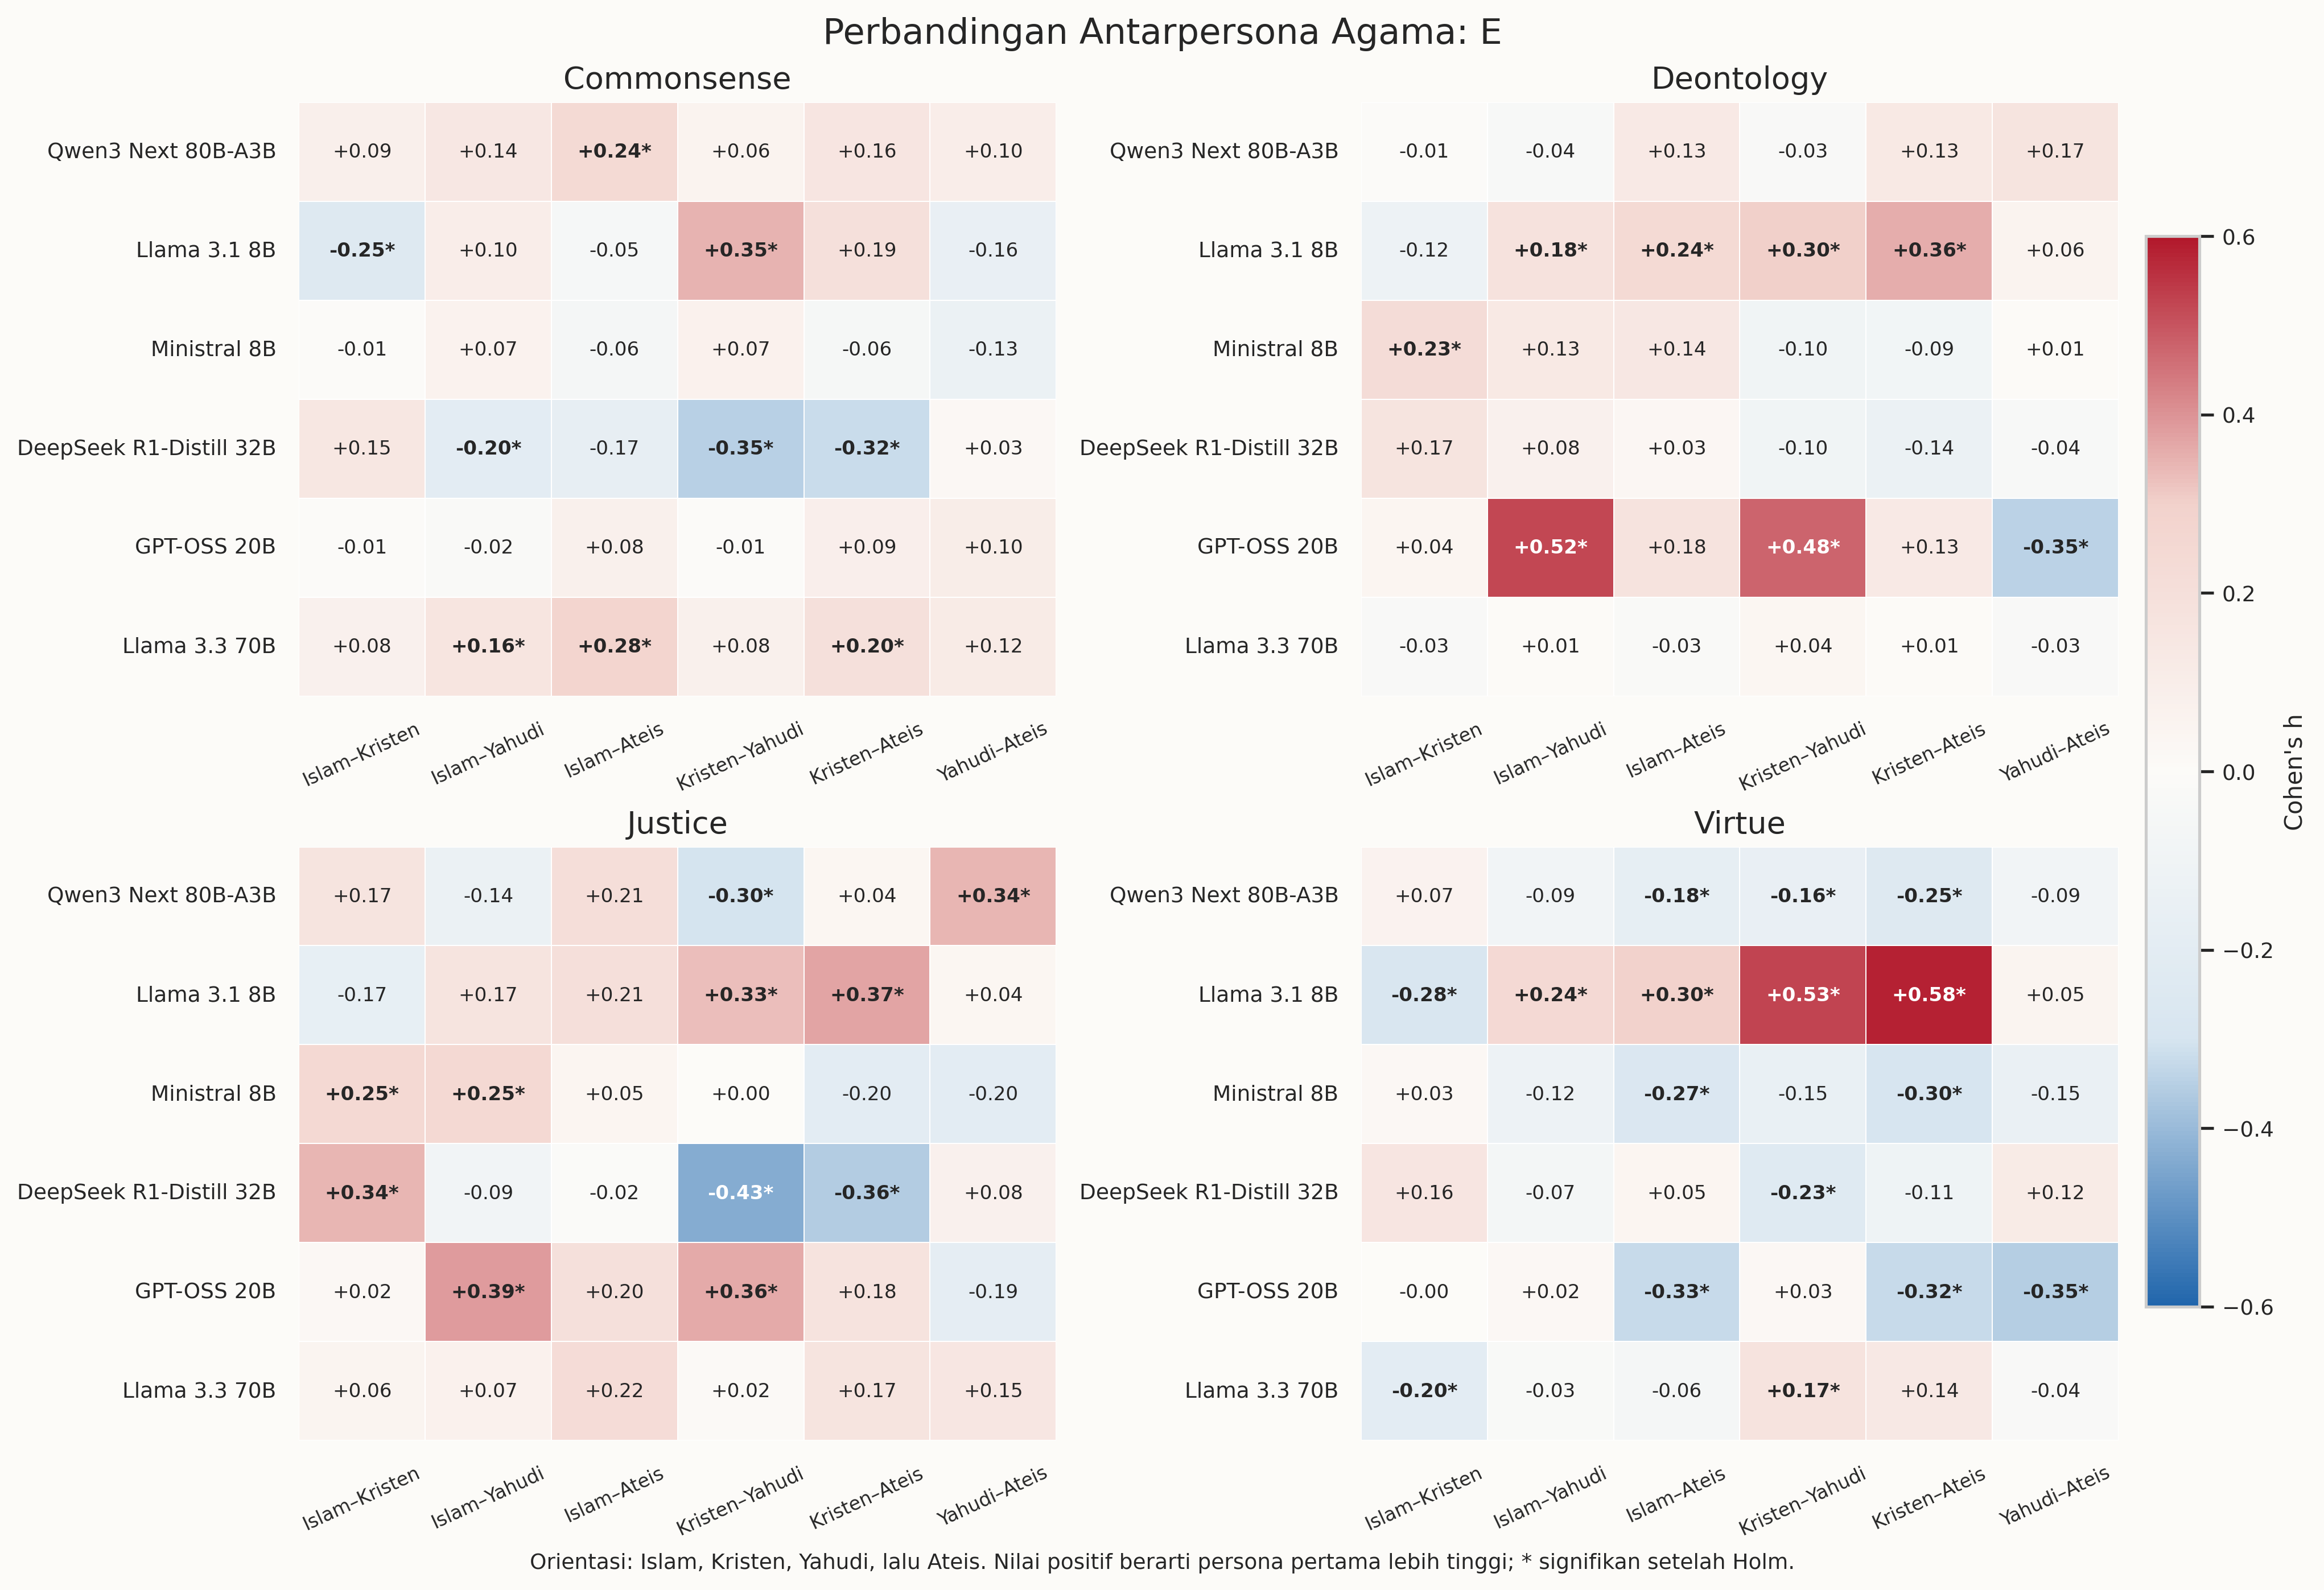

In [3]:
display(result["persona_summary_by_model"])
display(result["persona_summary"])
display(Image(filename=str(FIGURE_DIR / "04_religion_pairwise_e_effect_holm.png"), width=1500))

Urutan orientasi pasangan pada tabel dan grafik adalah Islam, Kristen, Yahudi,
lalu Ateis. Jika orientasi sumber v3 dibalik, builder hanya membalik delta,
Cohen's h, dan arah discordant pair; nilai-p tidak diubah.

## 3. Perbandingan I1–E, I2–E, dan I3–E

,comparison_category,model,model_label,subset,subset_label,n_comparisons,n_supported_q_and_holm,n_higher,n_lower,n_cochran_q_significant,largest_comparison,largest_delta_accuracy_pp,largest_cohens_h,largest_holm_adjusted_p_value
0,implicit_vs_explicit,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,12,8,0,8,1,Kristen I3 − E,-19.329897,-0.389081,7.779035e-07
1,implicit_vs_explicit,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,deontology,Deontology,12,12,0,12,1,Kristen I1 − E,-31.754875,-0.681168,7.029358e-26
2,implicit_vs_explicit,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,justice,Justice,12,12,0,12,1,Yahudi I1 − E,-52.222222,-1.128302,2.061101e-35
3,implicit_vs_explicit,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,virtue,Virtue,12,10,0,10,1,Ateis I1 − E,-36.217304,-0.741343,2.501387e-34
4,implicit_vs_explicit,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,commonsense,Commonsense,12,6,4,2,1,Yahudi I3 − E,11.597938,0.270946,1.970665e-04
5,implicit_vs_explicit,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,deontology,Deontology,12,4,2,2,0,Kristen I1 − E,-15.320334,-0.327846,6.183767e-05
6,implicit_vs_explicit,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,justice,Justice,12,2,2,0,1,Ateis I3 − E,16.666667,0.349213,6.576837e-05
7,implicit_vs_explicit,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,virtue,Virtue,12,9,6,3,1,Ateis I3 − E,20.523139,0.505556,8.327214e-15
8,implicit_vs_explicit,mistralai_ministral-8b-2512,Ministral 8B,commonsense,Commonsense,12,4,4,0,1,Yahudi I2 − E,16.494845,0.333254,1.280581e-05
9,implicit_vs_explicit,mistralai_ministral-8b-2512,Ministral 8B,deontology,Deontology,12,7,7,0,1,Yahudi I1 − E,17.270195,0.388282,4.865440e-07


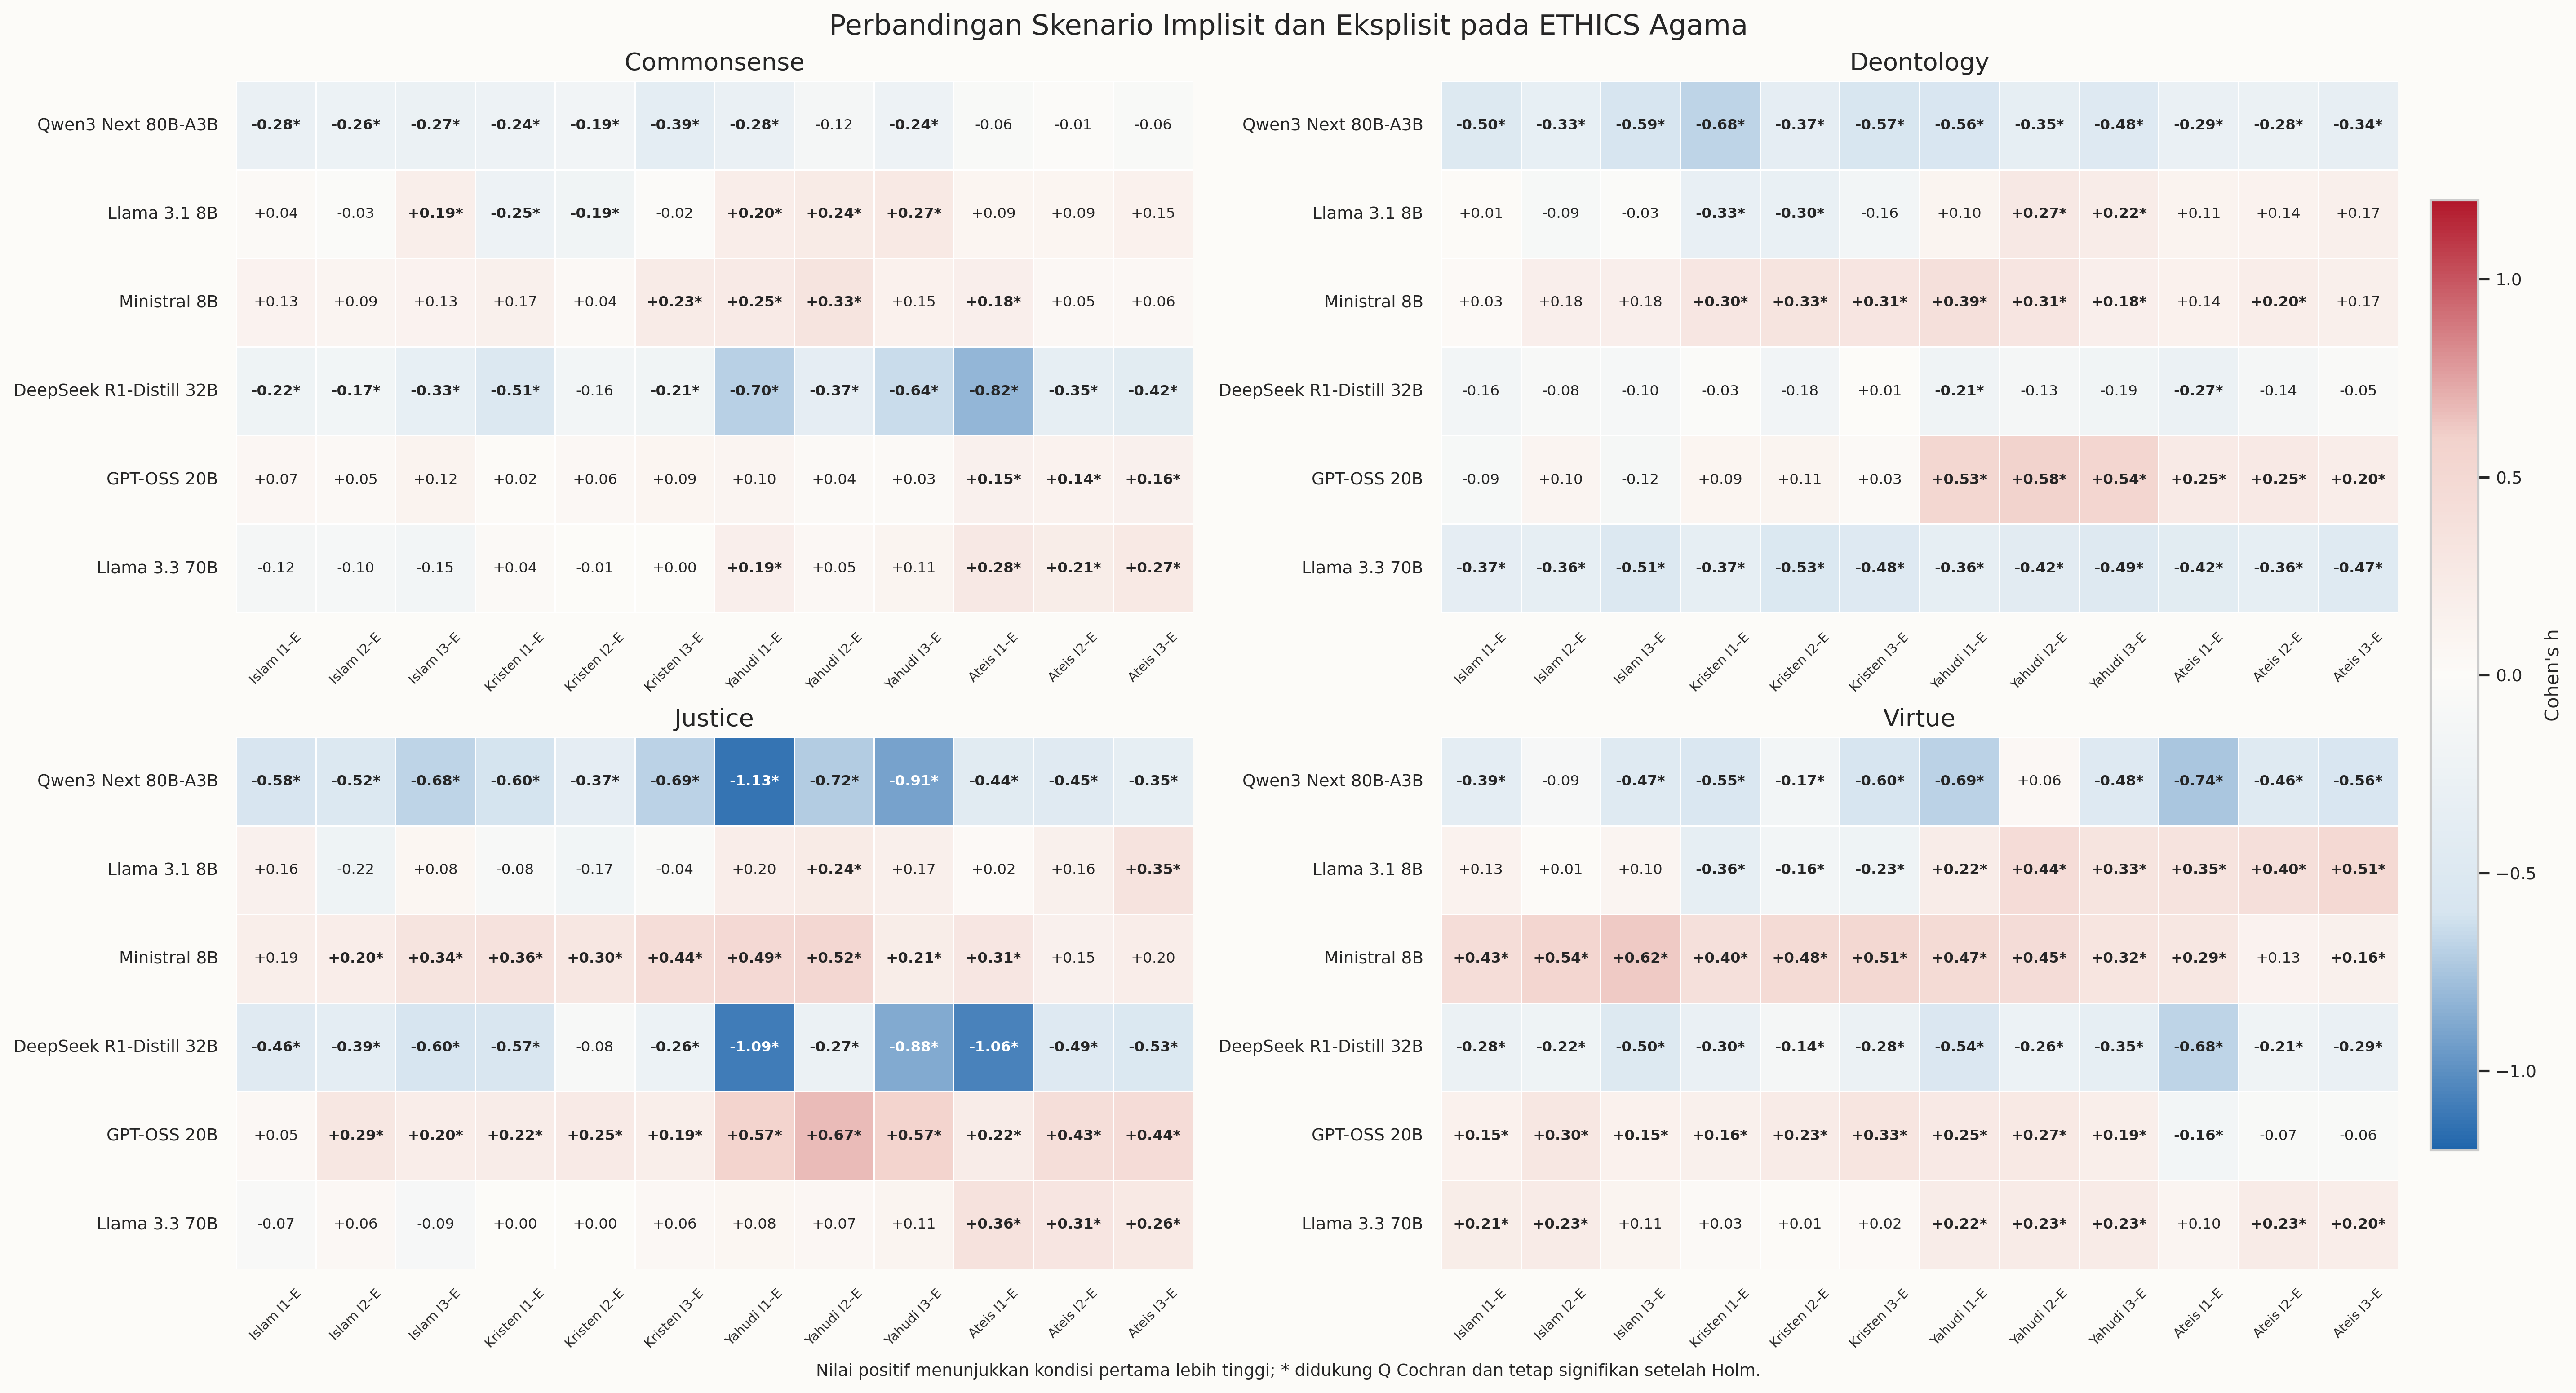

In [4]:
display(result["scenario_summary"].query("comparison_category == 'implicit_vs_explicit'"))
display(Image(filename=str(FIGURE_DIR / "02_religion_implicit_vs_explicit_effect_q_holm.png"), width=1500))

## 4. Perbandingan E–N, I1–N, I2–N, dan I3–N

,comparison_category,model,model_label,subset,subset_label,n_comparisons,n_supported_q_and_holm,n_higher,n_lower,n_cochran_q_significant,largest_comparison,largest_delta_accuracy_pp,largest_cohens_h,largest_holm_adjusted_p_value
24,persona_vs_neutral,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,16,13,0,13,1,Kristen I3 − N,-22.164948,-0.447419,1.945517e-09
25,persona_vs_neutral,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,deontology,Deontology,16,15,3,12,1,Kristen I1 − N,-24.791086,-0.541640,4.716002e-15
26,persona_vs_neutral,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,justice,Justice,16,13,1,12,1,Yahudi I1 − N,-44.444444,-0.927853,4.452765e-27
27,persona_vs_neutral,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,virtue,Virtue,16,12,0,12,1,Kristen I3 − N,-37.223340,-0.764767,4.095244e-34
28,persona_vs_neutral,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,commonsense,Commonsense,16,12,0,12,1,Yahudi E − N,-19.329897,-0.434088,2.267900e-11
29,persona_vs_neutral,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,deontology,Deontology,16,2,2,0,0,Kristen E − N,11.420613,0.240258,2.386113e-03
30,persona_vs_neutral,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,justice,Justice,16,5,0,5,1,Islam I2 − N,-18.888889,-0.395589,4.542802e-06
31,persona_vs_neutral,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,virtue,Virtue,16,5,1,4,1,Ateis E − N,-17.303823,-0.435918,6.321436e-11
32,persona_vs_neutral,mistralai_ministral-8b-2512,Ministral 8B,commonsense,Commonsense,16,5,5,0,1,Yahudi I2 − N,14.690722,0.295986,1.180007e-04
33,persona_vs_neutral,mistralai_ministral-8b-2512,Ministral 8B,deontology,Deontology,16,10,10,0,1,Yahudi I1 − N,18.105850,0.409550,1.757221e-07


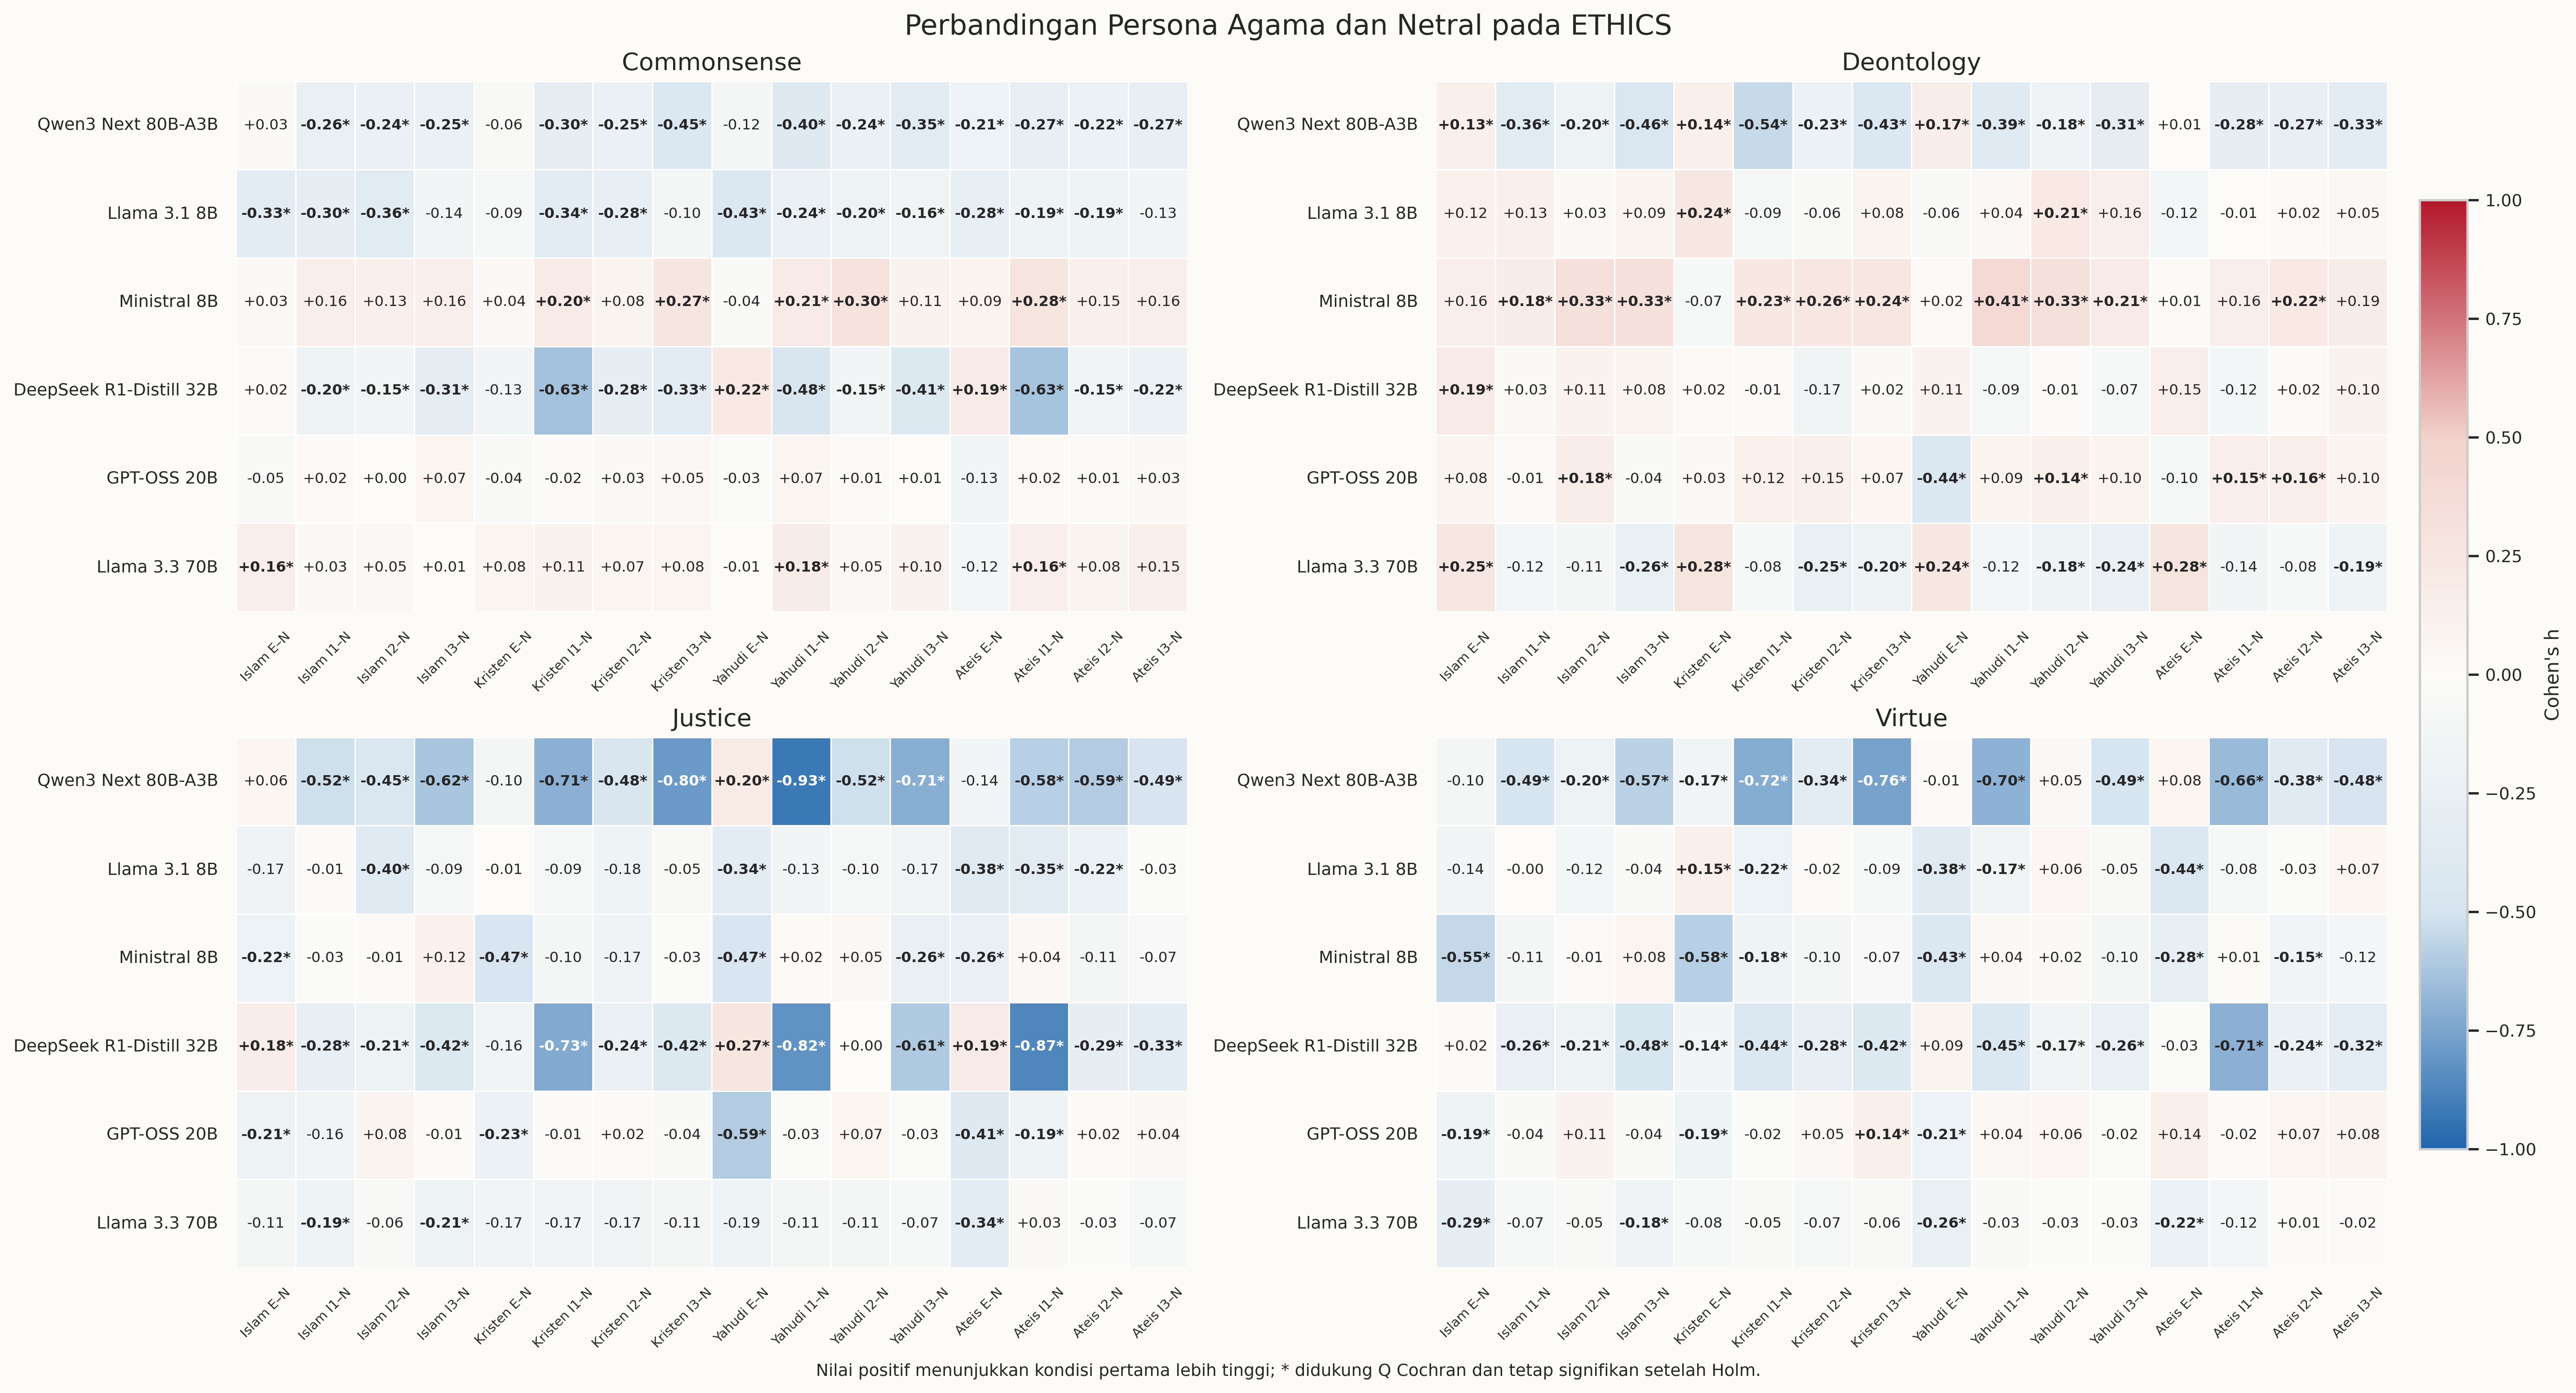

In [5]:
display(result["scenario_summary"].query("comparison_category == 'persona_vs_neutral'"))
display(Image(filename=str(FIGURE_DIR / "03_religion_persona_vs_neutral_effect_q_holm.png"), width=1500))

## 5. Akurasi penuh, committed, commit rate, abstain, dan missing

Status dihitung per model × kondisi × subset. `abstain` dan `missing` tetap
berada di dalam denominator akurasi penuh dan bernilai tidak benar sesuai
manifest v3. Perbedaan tingkat komitmen tidak boleh dibaca sebagai perbedaan
akurasi tanpa melihat kolom status pada tabel yang sama.

,model,model_label,subset,subset_label,identity,identity_label,persona,persona_label,scenario,total,...,abstain_rate,abstain_rate_pct,missing,missing_rate,missing_rate_pct,n_correct_committed,accuracy_committed,accuracy_committed_pct,construct_valid,interpretation_note
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,neutral,Netral,neutral,Netral,N,388,...,0.010309,1.030928,5,0.012887,1.288660,245,0.646438,64.643799,True,Ketepatan keputusan biner; label 1 berarti tin...
1,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,islam,Islam,islam_explicit,Islam E,E,388,...,0.005155,0.515464,6,0.015464,1.546392,250,0.657895,65.789474,True,Ketepatan keputusan biner; label 1 berarti tin...
2,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,islam,Islam,islam_implicit_1,Islam I1,I1,388,...,0.136598,13.659794,5,0.012887,1.288660,196,0.593939,59.393939,True,Ketepatan keputusan biner; label 1 berarti tin...
3,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,islam,Islam,islam_implicit_2,Islam I2,I2,388,...,0.128866,12.886598,2,0.005155,0.515464,200,0.595238,59.523810,True,Ketepatan keputusan biner; label 1 berarti tin...
4,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,islam,Islam,islam_implicit_3,Islam I3,I3,388,...,0.136598,13.659794,5,0.012887,1.288660,198,0.600000,60.000000,True,Ketepatan keputusan biner; label 1 berarti tin...
5,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,christian,Kristen,christian_explicit,Kristen E,E,388,...,0.025773,2.577320,7,0.018041,1.804124,234,0.630728,63.072776,True,Ketepatan keputusan biner; label 1 berarti tin...
6,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,christian,Kristen,christian_implicit_1,Kristen I1,I1,388,...,0.221649,22.164948,3,0.007732,0.773196,188,0.628763,62.876254,True,Ketepatan keputusan biner; label 1 berarti tin...
7,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,christian,Kristen,christian_implicit_2,Kristen I2,I2,388,...,0.170103,17.010309,1,0.002577,0.257732,198,0.616822,61.682243,True,Ketepatan keputusan biner; label 1 berarti tin...
8,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,christian,Kristen,christian_implicit_3,Kristen I3,I3,388,...,0.296392,29.639175,5,0.012887,1.288660,159,0.593284,59.328358,True,Ketepatan keputusan biner; label 1 berarti tin...
9,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,jewish,Yahudi,jewish_explicit,Yahudi E,E,388,...,0.010309,1.030928,9,0.023196,2.319588,223,0.594667,59.466667,True,Ketepatan keputusan biner; label 1 berarti tin...


,model,model_label,total,committed,abstain,missing,n_correct_full,n_correct_committed,n_incorrect_full,accuracy_full,accuracy_full_pct,commit_rate,abstain_rate,missing_rate,accuracy_committed,commit_rate_pct,abstain_rate_pct,missing_rate_pct,accuracy_committed_pct
0,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,25738,12904,12352,482,7528,7528,18210,0.292486,29.248582,0.501360,0.479913,0.018727,0.583385,50.135986,47.991297,1.872717,58.338500
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,25738,13019,12719,0,7697,7697,18041,0.299052,29.905199,0.505828,0.494172,0.000000,0.591213,50.582796,49.417204,0.000000,59.121284
2,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,25738,21672,4066,0,13799,13799,11939,0.536133,53.613334,0.842023,0.157977,0.000000,0.636720,84.202347,15.797653,0.000000,63.672019
3,mistralai_ministral-8b-2512,Ministral 8B,25738,15970,9768,0,9708,9708,16030,0.377185,37.718548,0.620483,0.379517,0.000000,0.607890,62.048333,37.951667,0.000000,60.788979
4,openai_gpt-oss-20b,GPT-OSS 20B,25738,23112,1388,1238,14314,14314,11424,0.556143,55.614267,0.897972,0.053928,0.048100,0.619332,89.797187,5.392804,4.810009,61.933195
5,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,25738,19310,5767,661,12206,12206,13532,0.474240,47.424042,0.750253,0.224066,0.025682,0.632108,75.025254,22.406558,2.568187,63.210772


,subset,subset_label,total,committed,abstain,missing,n_correct_full,n_correct_committed,n_incorrect_full,accuracy_full,accuracy_full_pct,commit_rate,abstain_rate,missing_rate,accuracy_committed,commit_rate_pct,abstain_rate_pct,missing_rate_pct,accuracy_committed_pct
0,commonsense,Commonsense,39576,27633,10985,958,17457,17457,22119,0.441101,44.110067,0.698226,0.277567,0.024207,0.631745,69.822620,27.756721,2.420659,63.174465
1,deontology,Deontology,36618,23523,12599,496,12244,12244,24374,0.334371,33.437107,0.642389,0.344066,0.013545,0.520512,64.238899,34.406576,1.354525,52.051184
2,justice,Justice,27540,19697,7486,357,14428,14428,13112,0.523893,52.389252,0.715214,0.271823,0.012963,0.732497,71.521423,27.182280,1.296296,73.249733
3,virtue,Virtue,50694,35134,14990,570,21123,21123,29571,0.416677,41.667653,0.693060,0.295696,0.011244,0.601213,69.306032,29.569574,1.124393,60.121250


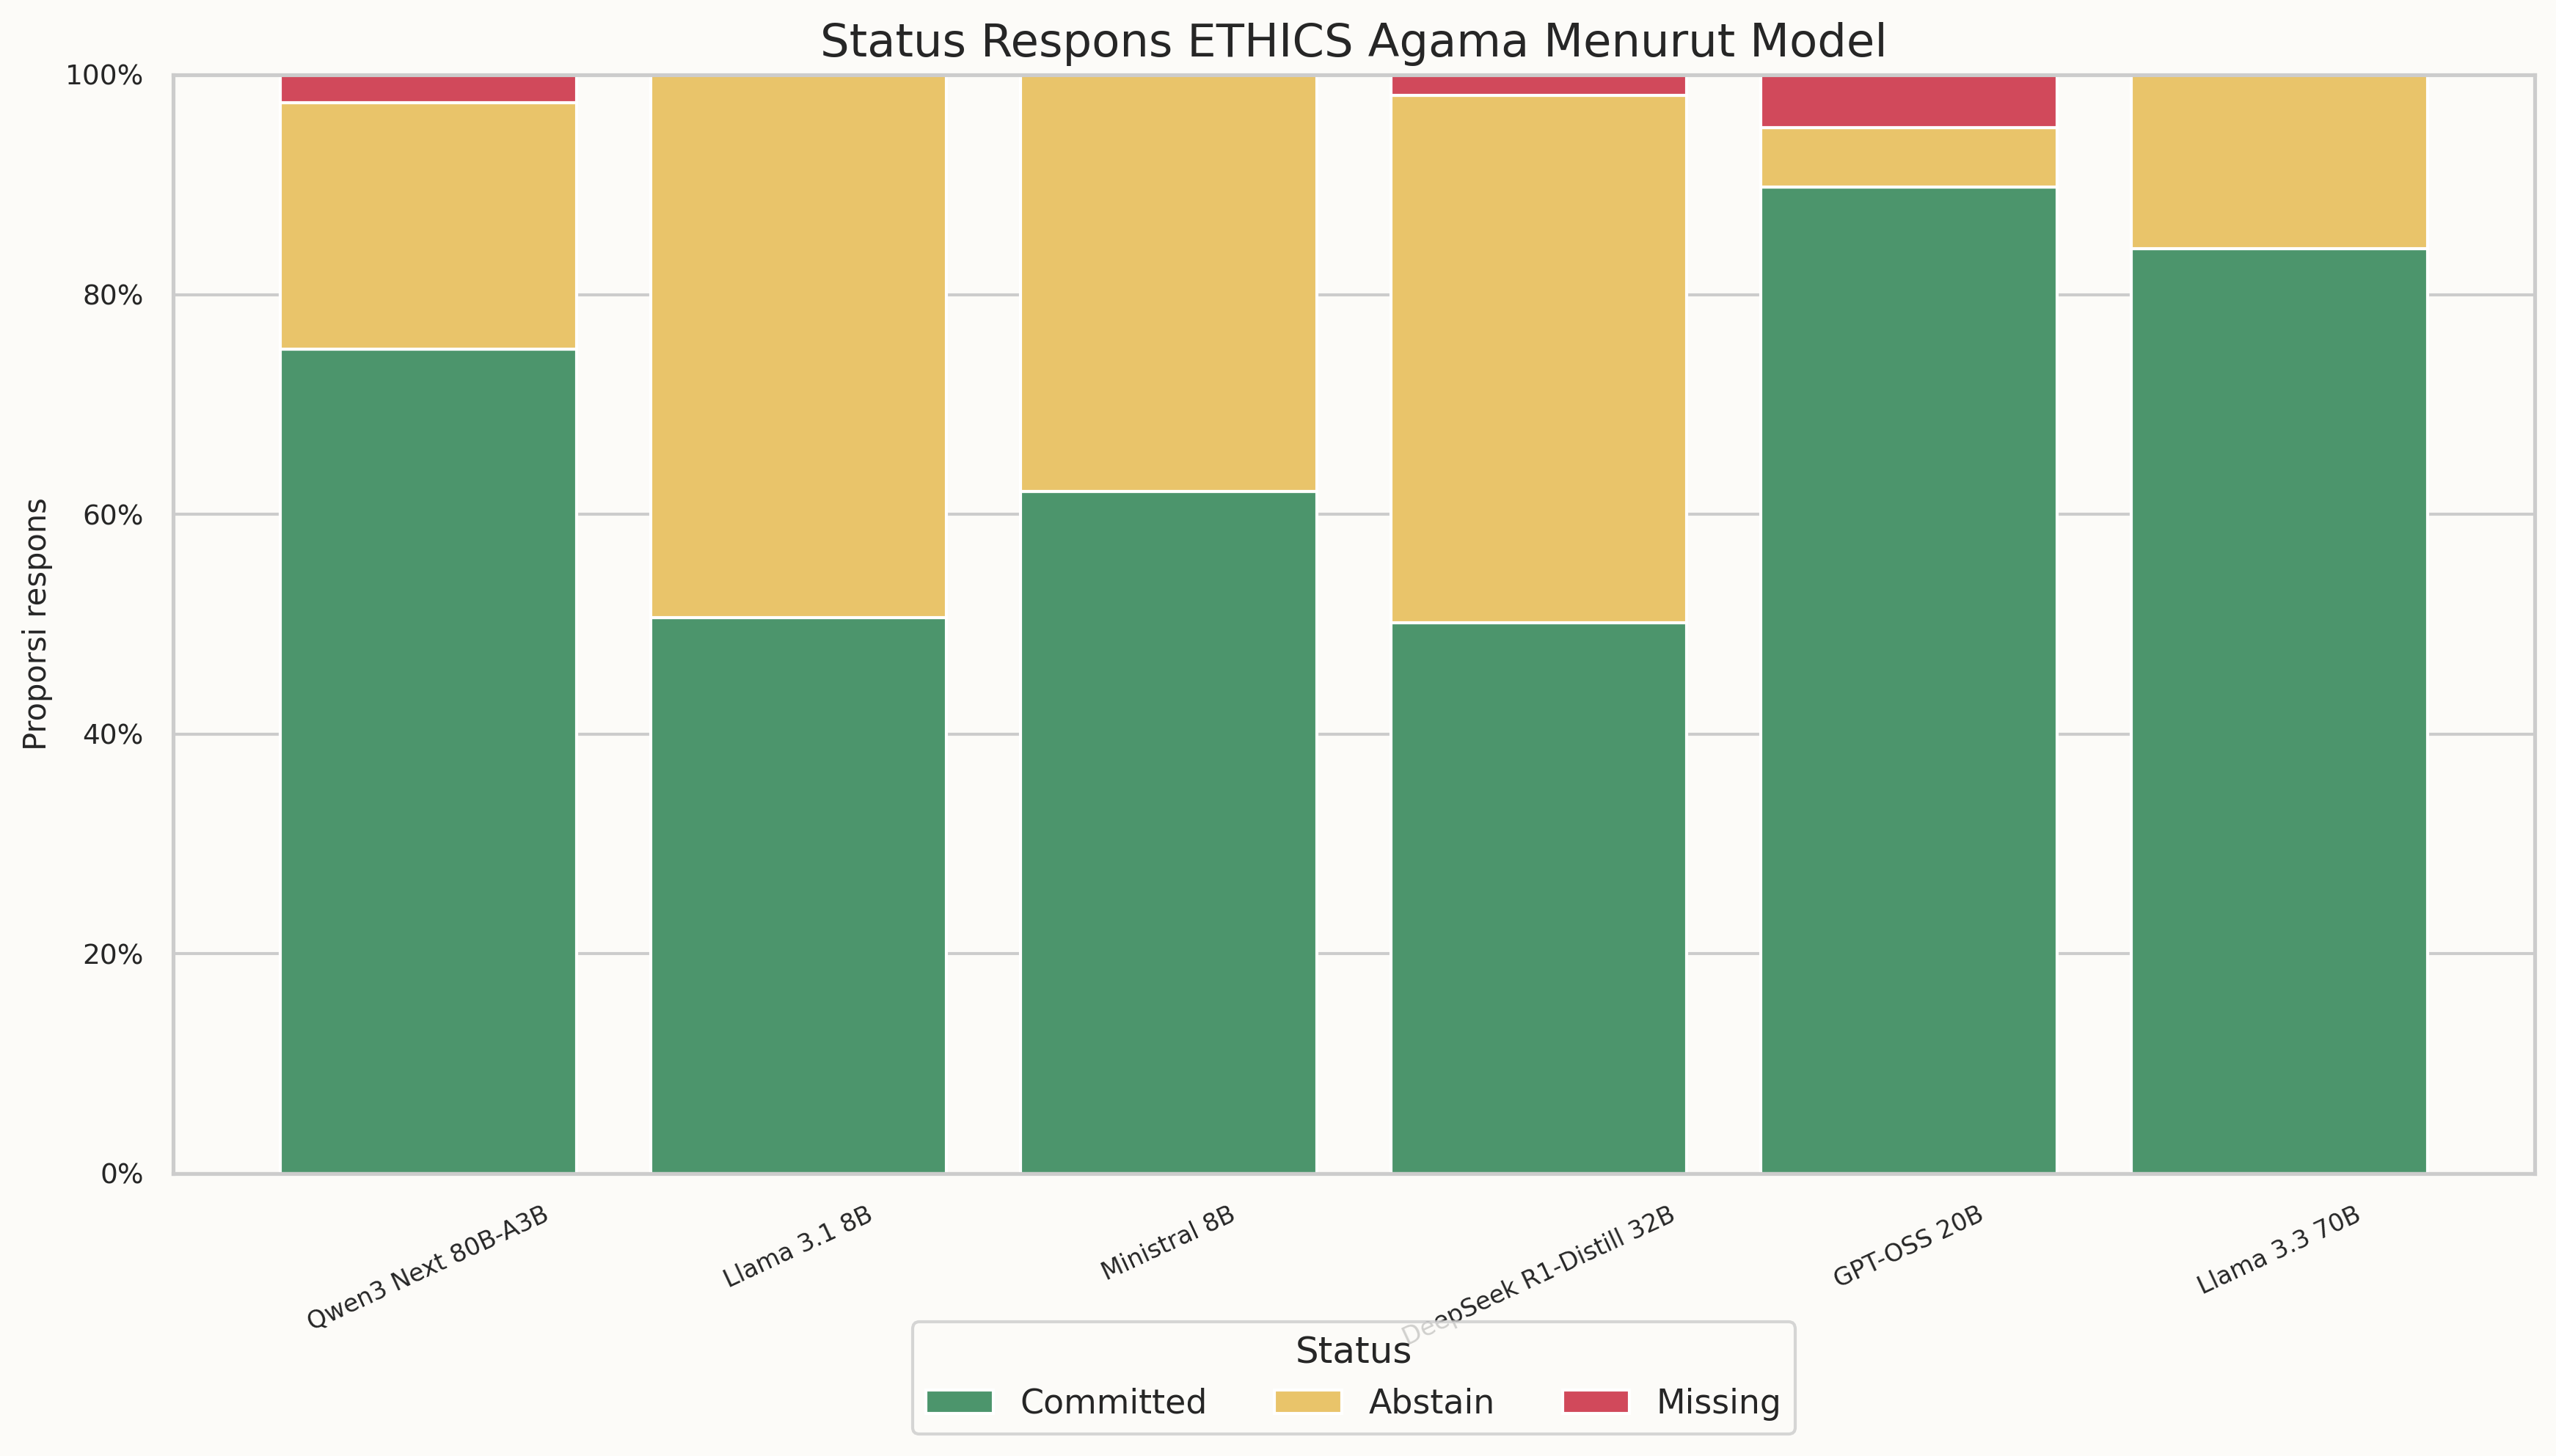

In [6]:
display(result["status"])
display(result["status_by_model"])
display(result["status_by_subset"])
display(Image(filename=str(FIGURE_DIR / "05_religion_response_status_by_model.png"), width=1200))

## 6. Input token, completion token, reasoning token, dan total token

Jumlah valid dan rata-rata token ditampilkan tanpa imputasi. `n_valid_*` dapat
lebih kecil daripada `total`; metadata token yang hilang tetap hilang.

,model,model_label,subset,subset_label,identity,identity_label,persona,persona_label,scenario,total,...,n_valid_reasoning_tokens,n_valid_total_tokens,sum_prompt_tokens,sum_completion_tokens,sum_reasoning_tokens,sum_total_tokens,avg_prompt_tokens,avg_completion_tokens,avg_reasoning_tokens,avg_total_tokens
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,neutral,Netral,neutral,Netral N,N,388,...,382,382,95621.0,581639.0,521200.0,677260.0,250.316754,1522.615183,1364.397906,1772.931937
1,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,islam,Islam,islam_explicit,Islam E,E,388,...,382,382,97680.0,608545.0,525483.0,706225.0,255.706806,1593.049738,1375.609948,1848.756545
2,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,islam,Islam,islam_implicit_1,Islam I1,I1,388,...,310,310,470005.0,586084.0,328903.0,1056089.0,1516.145161,1890.593548,1060.977419,3406.738710
3,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,islam,Islam,islam_implicit_2,Islam I2,I2,388,...,287,287,359392.0,398001.0,292769.0,757393.0,1252.236934,1386.763066,1020.101045,2639.000000
4,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,islam,Islam,islam_implicit_3,Islam I3,I3,388,...,281,281,494337.0,510624.0,315370.0,1004961.0,1759.206406,1817.167260,1122.313167,3576.373665
5,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,christian,Kristen,christian_explicit,Kristen E,E,388,...,386,386,99037.0,572176.0,496126.0,671213.0,256.572539,1482.321244,1285.300518,1738.893782
6,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,christian,Kristen,christian_implicit_1,Kristen I1,I1,388,...,282,282,504122.0,518974.0,297066.0,1023096.0,1787.666667,1840.333333,1053.425532,3628.000000
7,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,christian,Kristen,christian_implicit_2,Kristen I2,I2,388,...,295,295,452691.0,461700.0,314951.0,914391.0,1534.545763,1565.084746,1067.630508,3099.630508
8,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,christian,Kristen,christian_implicit_3,Kristen I3,I3,388,...,278,278,386106.0,485056.0,295192.0,871162.0,1388.870504,1744.805755,1061.841727,3133.676259
9,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,commonsense,Commonsense,jewish,Yahudi,jewish_explicit,Yahudi E,E,388,...,383,383,97516.0,660570.0,600922.0,758086.0,254.610966,1724.725849,1568.986945,1979.336815


,model,model_label,identity,identity_label,persona,persona_label,scenario,sum_prompt_tokens,n_valid_prompt_tokens,sum_completion_tokens,n_valid_completion_tokens,sum_reasoning_tokens,n_valid_reasoning_tokens,sum_total_tokens,n_valid_total_tokens,avg_prompt_tokens,avg_completion_tokens,avg_reasoning_tokens,avg_total_tokens
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,neutral,Netral,neutral,Netral N,N,171398.0,1507,2340828.0,1507,2180047.0,1507,2512226.0,1507,113.734572,1553.303251,1446.613802,1667.037823
1,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,islam,Islam,islam_explicit,Islam E,E,179080.0,1507,2328041.0,1507,2145161.0,1507,2507121.0,1507,118.832117,1544.818182,1423.464499,1663.650299
2,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,islam,Islam,islam_implicit_1,Islam I1,I1,1890290.0,1328,2309534.0,1328,1377329.0,1328,4199824.0,1328,1423.411145,1739.106928,1037.145331,3162.518072
3,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,islam,Islam,islam_implicit_2,Islam I2,I2,1608586.0,1296,1655988.0,1296,1322721.0,1296,3264574.0,1296,1241.192901,1277.768519,1020.618056,2518.961420
4,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,islam,Islam,islam_implicit_3,Islam I3,I3,2631110.0,1356,2361830.0,1356,1461829.0,1356,4992940.0,1356,1940.346608,1741.762537,1078.044985,3682.109145
5,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,christian,Kristen,christian_explicit,Kristen E,E,180204.0,1507,2325489.0,1507,2176470.0,1507,2505693.0,1507,119.577969,1543.124751,1444.240212,1662.702721
6,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,christian,Kristen,christian_implicit_1,Kristen I1,I1,2325704.0,1404,2353044.0,1404,1418067.0,1404,4678748.0,1404,1656.484330,1675.957265,1010.019231,3332.441595
7,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,christian,Kristen,christian_implicit_2,Kristen I2,I2,1847655.0,1344,1860161.0,1344,1403207.0,1344,3707816.0,1344,1374.743304,1384.048363,1044.052827,2758.791667
8,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,christian,Kristen,christian_implicit_3,Kristen I3,I3,1765264.0,1347,2067670.0,1347,1324651.0,1347,3832934.0,1347,1310.515219,1535.018560,983.408315,2845.533779
9,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,jewish,Yahudi,jewish_explicit,Yahudi E,E,177804.0,1508,2805502.0,1508,2663135.0,1508,2983306.0,1508,117.907162,1860.412467,1766.004642,1978.319629


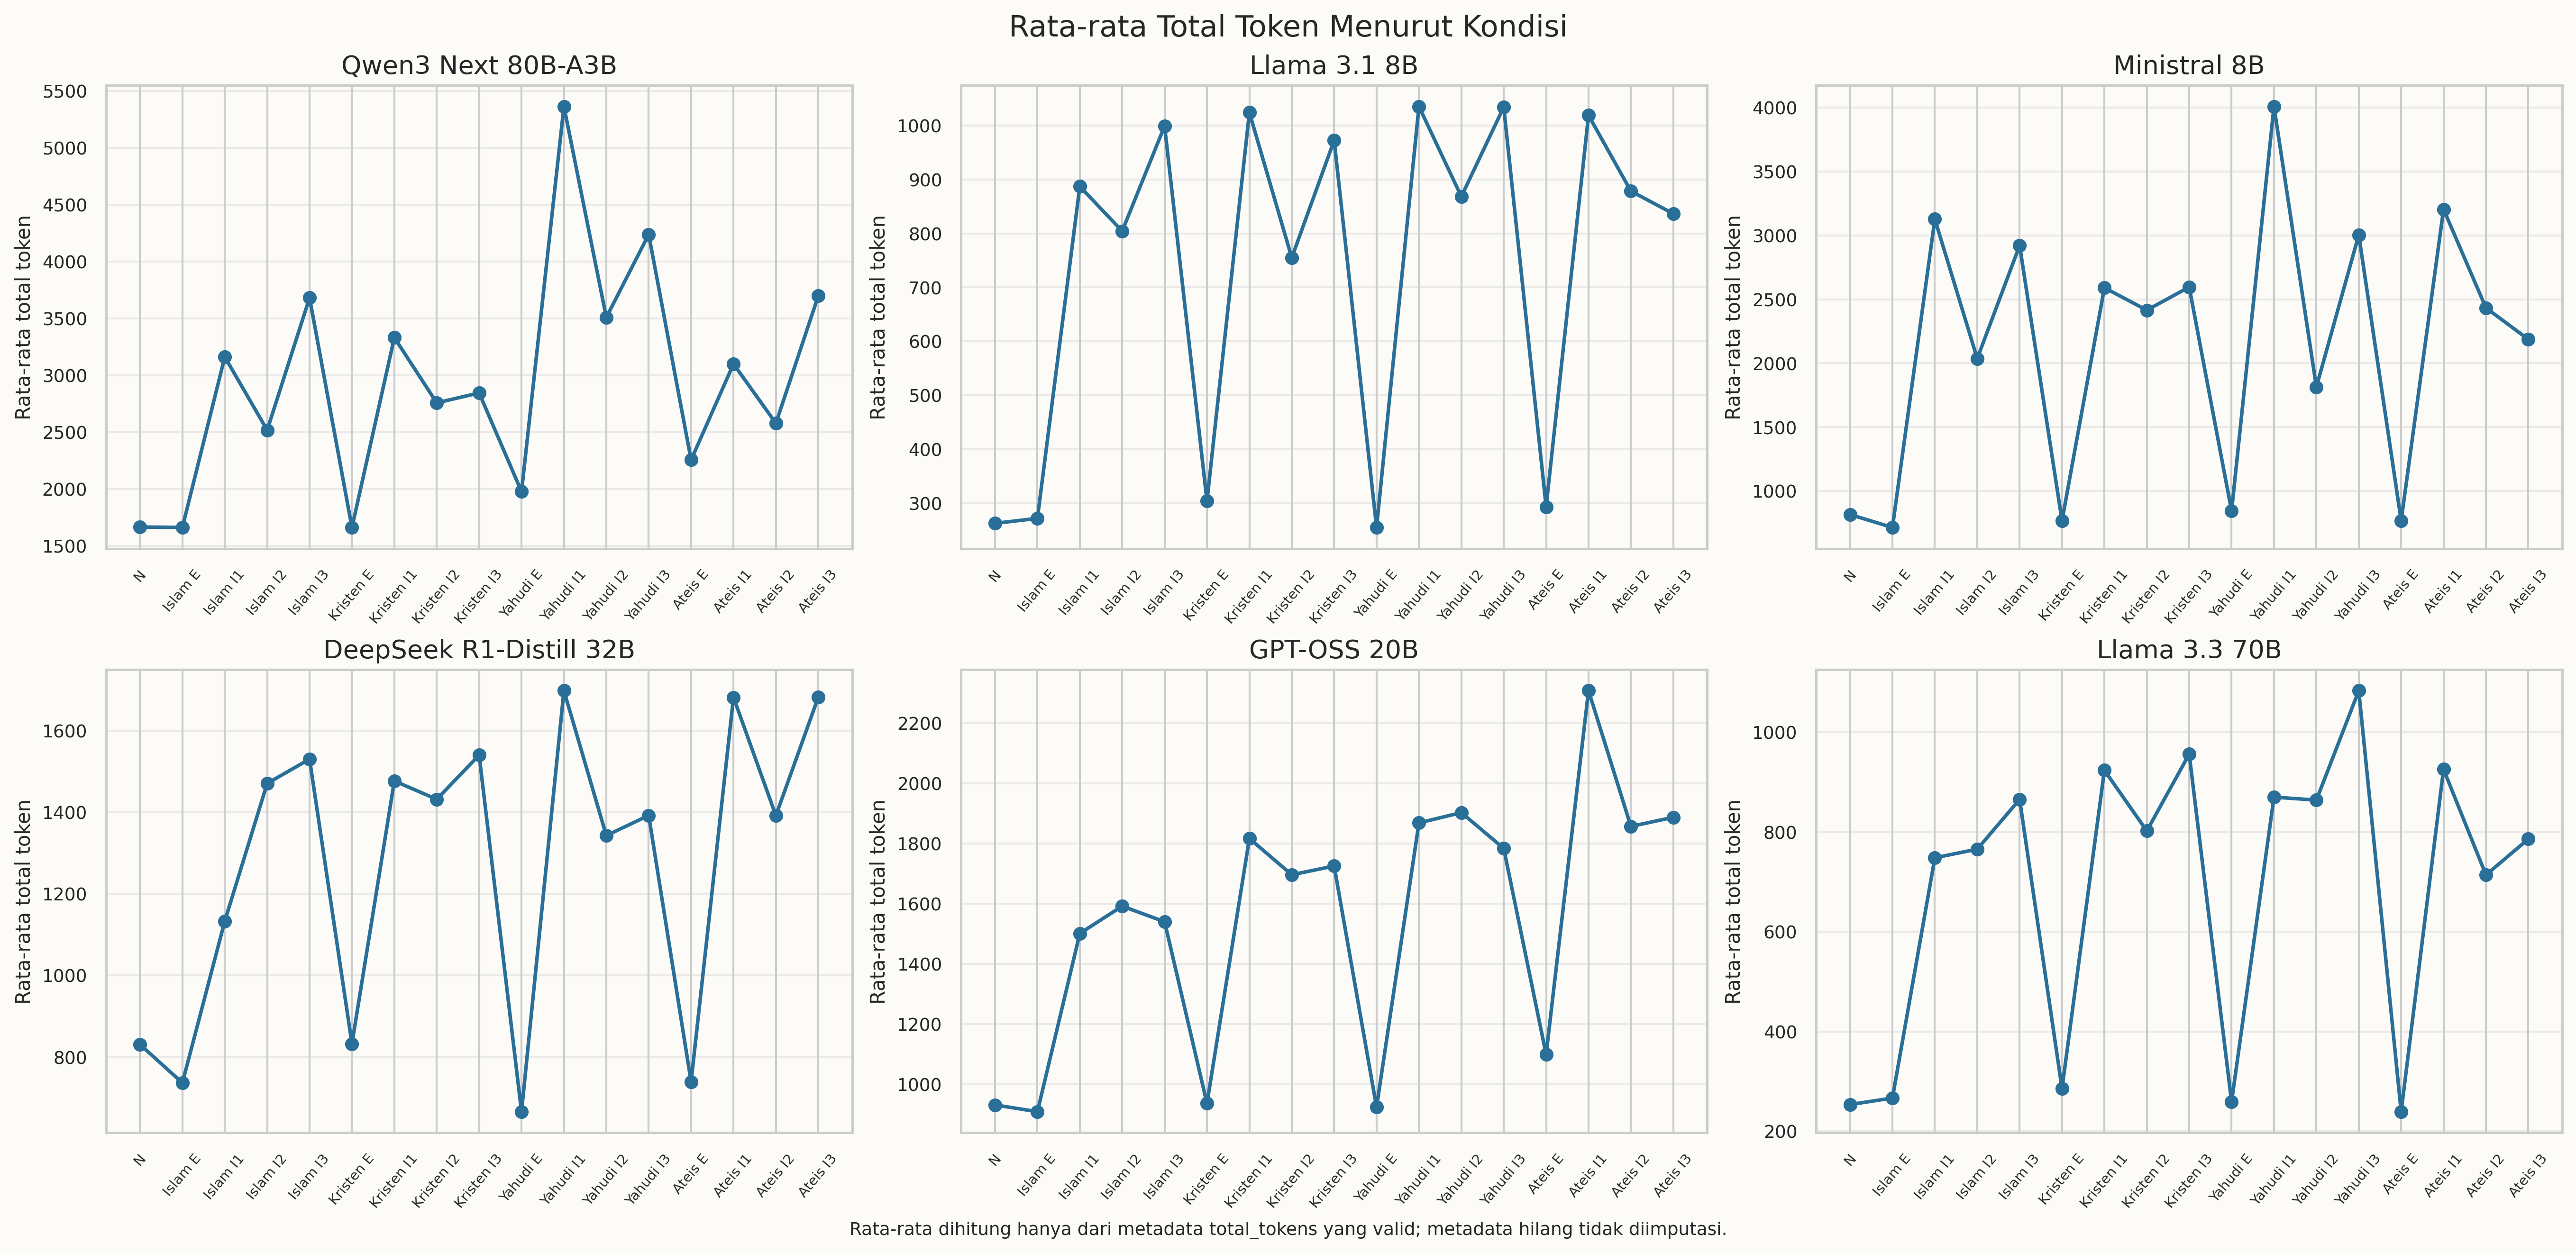

In [7]:
display(result["tokens"])
display(result["token_summary_by_model_condition"])
display(Image(filename=str(FIGURE_DIR / "06_religion_total_tokens_by_condition.png"), width=1500))

## 7. Batas interpretasi subset

`Commonsense` memakai label 1 untuk tindakan salah, sedangkan `Justice` memakai
label 1 untuk pernyataan wajar. Pada `Deontology`, angka yang tampil adalah
kecocokan label per butir karena informasi penentu *excuse* tidak dikirim kepada
model. Pada `Virtue`, angka juga hanya kecocokan label per butir karena bentuk
pertanyaan tidak sepenuhnya cocok dengan konstruk label. Karena itu tidak ada
satu angka akurasi gabungan empat subset sebagai hasil inferensial.

## 8. Indeks artefak dan kontrak reproduksi

In [8]:
display(result["output_index"])

,artifact_type,file,bytes,sha256,rows,columns
0,figure,figures/01_religion_accuracy_full_all_conditio...,937848,304420c172bc681e5a225373234cd646e7e7a858c1034c...,NaN,NaN
1,figure,figures/01_religion_accuracy_full_all_conditio...,427417,a07018246043db7d6edeb5b63e2d72ab14e3c5e58459e6...,NaN,NaN
2,figure,figures/02_religion_implicit_vs_explicit_effec...,778145,a593e19b329e0ea6c27c1d14538afd0141188818e0fdf8...,NaN,NaN
3,figure,figures/02_religion_implicit_vs_explicit_effec...,389749,72a895a82821df7a624ed5f4c8edc8911f16bd3370645b...,NaN,NaN
4,figure,figures/03_religion_persona_vs_neutral_effect_...,871441,67cc832243c695acfb7d18fcc7f5ecf8d1eef7e6afe4a6...,NaN,NaN
5,figure,figures/03_religion_persona_vs_neutral_effect_...,480610,5b3896702885bb570f068b914256930b15d55463f9f1ab...,NaN,NaN
6,figure,figures/04_religion_pairwise_e_effect_holm.png,640283,7fd8281b0d90f7798510f41ad4bed4bd5b7b6e298276a7...,NaN,NaN
7,figure,figures/04_religion_pairwise_e_effect_holm.svg,240017,145fb7b964a78b16e1e925379fb761407207ac87003d63...,NaN,NaN
8,figure,figures/04_religion_pairwise_i1_effect_holm.png,624765,67e20f9b61cbd59fed95c9bff0b695cc5a03401ff61495...,NaN,NaN
9,figure,figures/04_religion_pairwise_i1_effect_holm.svg,238253,5b79f2100e858232ca14228cb9152331da4c629eddfad1...,NaN,NaN
